# Modelación

Modelación utilizando arquitecturas de redes neuronales.

## Configuración

In [ ]:
!pip install -q bayesian-optimization
!pip install -U hyperopt
!pip install statsforecast
!pip install neuralforecast


Looking in indexes: https://download.pytorch.org/whl/cu126
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 108.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.7/897.7 kB 146.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 190.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 571.0/571.0 MB 62.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 393.1/393.1 MB 38.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.2/200.2 MB 50.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 19.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 158.2/158.2 MB 72.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.6/216.6 MB 56.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.8/156.8 MB 68.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.7/188.7 MB 45.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.3/8

In [ ]:
#############
# librerias #
#############

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
import math
import logging
import ray

from neuralforecast.tsdataset import TimeSeriesDataset
from ray import tune
from neuralforecast import NeuralForecast
from neuralforecast.losses.pytorch import MASE, DistributionLoss, QuantileLoss, MSE
from neuralforecast.auto import AutoLSTM, AutoDeepAR, AutoTFT, AutoInformer, AutoAutoformer, AutoTCN

Mounted at /content/drive


In [ ]:
###################
# Configuraciones #
###################

# Parametros para las series de tiempo
ts_freq = 'W'
ts_freq2 = 52

# Semanas epidemiologicas de las olas
ola_1 = '2020_08_2020_39'
ola_2 = '2020_40_2021_15'
ola_3 = '2021_23_2021_42'
ola_4 = '2021_51_2022_09'
ola_5 = '2022_22_2022_33'
ola_6 = '2022_49_2023_04'

# Periodo de tiempo para pronosticar el consumo al acabar la pandemia
ola_all = '2020_12_2023_18'
ola_all2 = '2022_09_2023_18'

# Periodos para los analisis retrospectivos
ola_retro_1 = '2020_08_2020_39'
ola_retro_2 = '2020_12_2021_35'
ola_retro_3 = '2020_12_2022_09'

# Lista de variables exogenas
lista_exog = ['F_INER', 'M_INER', 'F_CASOS', 'M_CASOS', 'FLAG_OLA', 'FLAG_VAC']
lista_cons = ['FLAG_VAC']

# Medicamento a probar: FENTANIL, MIDAZOLAM, PARACETAMOL
ruta_med = 'PARACETAMOL'

# Semila para replicas
np.random.seed(1)

# Listado de medicamentos
lista_med = ["FENTANIL", "MIDAZOLAM", "PARACETAMOL"]

# Quantil contemplado para los pronosticos (en caso de ser requerido)
aux_ql = 0.75

# Listado de funciones de perdida
lista_loss = [MSE(), MASE(1), QuantileLoss(aux_ql)]

# Listado de periodos de tiempo a pronosticar
lista_per = [1, 4, 12]

# Listado de modelos
lista_mod = ["AutoETS", "AutoARIMA", "LSTM", "DeepAR", "TFT", "Informer", "Autoformer", "TCN"]

In [ ]:
##################
# Carga de datos #
##################

# Carga de datos de pacientes
# datos_econo = pd.read_csv()

# Carga de datos de casos confirmados
# datos_casos = pd.read_csv()

# Carga de series de tiempo de insumos medicos
# datos_cost = pd.read_csv()


# Se crea la tabla principal con las series

# Se agrega el numero de ingresos al INER
datos_series = pd.merge(datos_cost, datos_econo, left_on = ['FECHA'], right_on = ['FECHA_INGRESO_INER'], how = 'left')
datos_series.drop(columns = ['FECHA_INGRESO_INER'], inplace = True)

# Se agrega el numero de casos
datos_series = pd.merge(datos_series, datos_casos, left_on = ['FECHA'], right_on = ['FECHA_INGRESO'], how = 'left', suffixes=('_INER', '_CASOS'))
datos_series.drop(columns = ['FECHA_INGRESO'], inplace = True)

# Se asigna la semana epidemiologica
datos_series['SEMANA_EPIDEM']  = datos_series['FECHA'].dt.isocalendar().week

# Se agrega una bandera para indicar la presencia de las olas de contagio
olas = [ola_1, ola_2, ola_3, ola_4, ola_5, ola_6]
for r in range(0,6):

  aux_fin = datetime.datetime.strptime(olas[r][8:12] + ' ' +  olas[r][13:17] + ' 1', "%Y %W %w")
  aux_ini = datetime.datetime.strptime(olas[r][0:4] + ' ' +  olas[r][5:7] + ' 1', "%Y %W %w")
  datos_series.loc[(aux_ini <= datos_series['FECHA']) & (datos_series['FECHA'] <= aux_fin), 'FLAG_OLA'] = 1

# Se agrega una bandera para indicar la aplicacion de la vacuna contra COVID-19:
datos_series.loc['2020/12/23' <= datos_series['FECHA'], 'FLAG_VAC'] = 1

# Se rellanan valores con Nan con 0's
datos_series.fillna(0, inplace = True)

datos_series.reset_index(drop=True)


/tmp/ipykernel_8865/2378006066.py:37: DtypeWarning: Columns (0,1,7) have mixed types. Specify dtype option on import or set low_memory=False.
  datos_cost = pd.read_csv("/content/drive/My Drive/Limpieza_Datos/ABT/datos_costos_st_covid.csv", converters={'COD_CARGO':str},)
/tmp/ipykernel_8865/2378006066.py:58: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  datos_econo = datos_econo.groupby(['FECHA_INGRESO_INER', 'SEXO']).agg(NUMERO_INGRESOS = ('NOMBRE_DEL_PACIENTE','size')).reset_index()


,FECHA,FENTANIL_1,MIDAZOLAM_1,MIDAZOLAM_2,MIDAZOLAM_3,PARACETAMOL_1,PARACETAMOL_2,PARACETAMOL_3,PARACETAMOL_5,PARACETAMOL,FENTANIL,MIDAZOLAM,F_INER,M_INER,F_CASOS,M_CASOS,SEMANA_EPIDEM,FLAG_OLA,FLAG_VAC
0,2020-02-24,0.0,0.0,0.0,0.0,10.0,20.0,0.0,0.0,3.401197,0.000000,0.000000,0.000000,0.000000,1.098612,1.945910,9,1.0,0.0
1,2020-03-02,0.0,0.0,0.0,0.0,10.0,0.0,0.0,0.0,2.302585,0.000000,0.000000,0.000000,0.000000,3.433987,3.218876,10,1.0,0.0
2,2020-03-09,60.0,387.0,0.0,0.0,130.0,0.0,10.0,0.0,4.941642,4.094345,5.958425,1.098612,1.098612,4.736198,4.962845,11,1.0,0.0
3,2020-03-16,576.0,2295.0,0.0,0.0,390.0,30.0,20.0,0.0,6.086775,6.356108,7.738488,0.000000,1.609438,5.710427,6.070738,12,1.0,0.0
4,2020-03-23,1360.0,6276.0,0.0,0.0,700.0,110.0,0.0,0.0,6.697034,7.215240,8.744488,2.079442,2.708050,6.469250,6.647688,13,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
162,2023-04-03,994.0,3465.0,30.0,0.0,1170.0,875.0,180.0,0.0,7.707512,6.901737,8.159089,1.386294,1.098612,8.514790,8.116118,14,0.0,1.0
163,2023-04-10,2.0,507.0,0.0,0.0,250.0,1765.0,150.0,0.0,7.680176,0.693147,6.228511,0.693147,1.791759,8.704171,8.259976,15,0.0,1.0
164,2023-04-17,346.0,1149.0,0.0,0.0,250.0,990.0,50.0,0.0,7.162397,5.846439,7.046647,1.098612,1.609438,8.641709,8.222016,16,0.0,1.0
165,2023-04-24,16.0,126.0,0.0,0.0,0.0,885.0,100.0,0.0,6.892642,2.772589,4.836282,0.693147,0.000000,8.659907,8.212297,17,0.0,1.0


## Modelación

### Selección de escenario

In [ ]:
##############
# Escenarios #
##############

# Horizonte de tiempo a pronosticar, Numero de fechas de validacion: debe ser mas pequenio, Numero de fechas de prueba, Refit y Espacio entre ventanas
def experimentos(id):
  global t, t_val, t_test, re_entrenar, prueba, t_step, n_samp

  # Prueba 1
  if id == 1:
    t = 12; t_val = 12; t_test = 12; re_entrenar = False; prueba = "Test_1"; t_step = t; n_samp = 50

  # Prueba 2
  elif id == 2:
    t = 4; t_val = 12; t_test = 12; re_entrenar = False; prueba = "Test_2"; t_step = t; n_samp = 50

  # Prueba 3
  elif id == 3:
    t = 1; t_val = 12; t_test = 12; re_entrenar = False; prueba = "Test_3"; t_step = t; n_samp = 50

  # Prueba 4
  elif id == 4:
    t = 12; t_val = 12; t_test = 12; re_entrenar = True; prueba = "Test_4"; t_step = t; n_samp = 50

  # Prueba 5
  elif id == 5:
    t = 4; t_val = 12; t_test = 12; re_entrenar = True; prueba = "Test_5"; t_step = t; n_samp = 50

  # Prueba 6
  elif id == 6:
    t = 1; t_val = 12; t_test = 12; re_entrenar = True; prueba = "Test_6"; t_step = t; n_samp =10

experimentos(1)

# Para el pronostico con entrenamiento reducido

# Paracetamol
#t = 1; t_val = 8; t_test = 8; re_entrenar = True; prueba = "Test_6"; t_step = t; n_samp =10

# Fentanil
#t = 1; t_val = 8; t_test = 8; re_entrenar = True; prueba = "Test_6"; t_step = t; n_samp =10

# Midazolam
#t = 4; t_val = 8; t_test = 8; re_entrenar = True; prueba = "Test_5"; t_step = t; n_samp =50

# Para el analisis retrospectivo 1
#t = 1; t_val = 3; t_test = 3; re_entrenar = True; prueba = "Retro_1"; t_step = t; n_samp =20

# Para el analisis retrospectivo 2
#t = 1; t_val = 8; t_test = 8; re_entrenar = True; prueba = "Retro_2"; t_step = t; n_samp =20

# Para el analisis retorspectivo 3
#t = 1; t_val = 8; t_test = 8; re_entrenar = True; prueba = "Retro_3"; t_step = t; n_samp =20

# Funcion de perdida
#func_loss = MSE()
#func_loss = MASE(seasonality = 1) # Se deja como el modelo naive mas sencillo
func_loss = QuantileLoss(aux_ql)

aux_ola = ola_all

aux_ola_fin = datetime.datetime.strptime(aux_ola[8:12] + ' ' +  aux_ola[13:17] + ' 1', "%Y %W %w")
aux_ola_ini = datetime.datetime.strptime(aux_ola[0:4] + ' ' +  aux_ola[5:7] + ' 1', "%Y %W %w")

# Particion de datos: entrenamiento y prueba
aux = datos_series.loc[(aux_ola_ini <= datos_series['FECHA']) & (datos_series['FECHA'] <= aux_ola_fin)].copy()
aux_fecha = aux['FECHA'].copy().reset_index(drop=True)

# Todas las variables para el entrenamiento
all_var = [ruta_med] + lista_exog

# Todas las variables para la evaluacion
all_var2 = ["PARACETAMOL", "MIDAZOLAM", "FENTANIL"] + lista_exog

# Datos para la evaluacion de los modelos
datos_eval = pd.DataFrame(aux[all_var2]).reset_index(drop=True)
datos_eval['ds'] = aux_fecha
datos_eval['unique_id'] = '1'

# Datos para el entrenamiento de los modelos
aux = pd.DataFrame(aux[all_var]).rename(columns = {ruta_med:'y'}).reset_index(drop=True)
aux['ds'] = aux_fecha
aux['unique_id'] = '1'
datos_modelado = aux.copy()

Y_train_df = aux[aux.ds<aux['ds'].values[-t]]
Y_test_df = aux[aux.ds>=aux['ds'].values[-t]].reset_index(drop=True)


### LSTM

+--------------------------------------------------------------------+
| Configuration for experiment     _train_tune_2026-03-31_01-03-07   |
+--------------------------------------------------------------------+
| Search algorithm                 SearchGenerator                   |
| Scheduler                        FIFOScheduler                     |
| Number of trials                 50                                |
+--------------------------------------------------------------------+

View detailed results here: /root/ray_results/_train_tune_2026-03-31_01-03-07
To visualize your results with TensorBoard, run: `tensorboard --logdir /tmp/ray/session_2026-03-30_16-47-30_802972_8865/artifacts/2026-03-31_01-03-07/_train_tune_2026-03-31_01-03-07/driver_artifacts`


2026-03-31 01:03:56,501	INFO tensorboardx.py:308 -- Removed the following hyperparameter values when logging to tensorboard: {'hist_exog_list': ('F_INER', 'M_INER', 'F_CASOS', 'M_CASOS', 'FLAG_OLA', 'FLAG_VAC'), 'loss': ('__ref_ph', '0bab4678'), 'valid_loss': ('__ref_ph', 'ab9d4548')}
2026-03-31 01:04:49,829	INFO tensorboardx.py:308 -- Removed the following hyperparameter values when logging to tensorboard: {'hist_exog_list': ('F_INER', 'M_INER', 'F_CASOS', 'M_CASOS', 'FLAG_OLA', 'FLAG_VAC'), 'loss': ('__ref_ph', '0bab4678'), 'valid_loss': ('__ref_ph', 'ab9d4548')}
2026-03-31 01:05:37,025	INFO tensorboardx.py:308 -- Removed the following hyperparameter values when logging to tensorboard: {'hist_exog_list': ('F_INER', 'M_INER', 'F_CASOS', 'M_CASOS', 'FLAG_OLA', 'FLAG_VAC'), 'loss': ('__ref_ph', '0bab4678'), 'valid_loss': ('__ref_ph', 'ab9d4548')}
2026-03-31 01:06:19,422	INFO tensorboardx.py:308 -- Removed the following hyperparameter values when logging to tensorboard: {'hist_exog_list'

┏━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name         ┃ Type          ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss         │ MSE           │      0 │ eval  │     0 │
│ 1 │ padder_train │ ConstantPad1d │      0 │ train │     0 │
│ 2 │ scaler       │ TemporalNorm  │      0 │ train │     0 │
│ 3 │ hist_encoder │ LSTM          │  4.0 K │ train │     0 │
│ 4 │ mlp_decoder  │ MLP           │     12 │ train │     0 │
└───┴──────────────┴───────────────┴────────┴───────┴───────┘

Trainable params: 4.1 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 4.1 K                                                                                                
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 6                                                                                           
Modules in eval mode: 1                                                                                            
Total FLOPs: 0

Output()

Output()

Output()

MAPE obtenido en los datos de validación:10.346153505303365


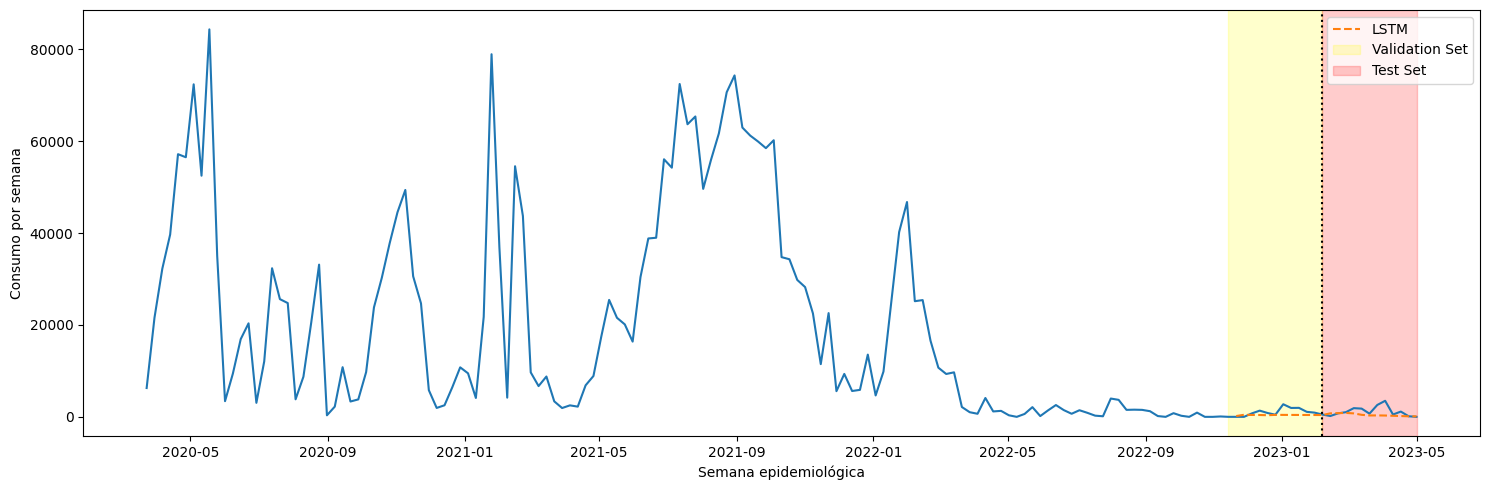

In [ ]:
########
# LSTM #
########

# Particion de datos para el automodelo
aux_train, *_ = TimeSeriesDataset.from_df(Y_train_df)
aux_test, *_ = TimeSeriesDataset.from_df(Y_test_df)

# Configuracion para las pruebas
aux_conf = {'input_size': tune.randint(4, 20), 'encoder_hidden_size': tune.randint(1, 20), 'encoder_n_layers': tune.randint(1, 8), 'decoder_layers': tune.randint(1, 8),
            'context_size': tune.randint(1, 8), 'decoder_hidden_size': tune.randint(1, 20), 'learning_rate': tune.loguniform(1e-4, 1e-1),
            'max_steps': tune.choice([200, 500]), 'batch_size': tune.randint(4, 20),  'random_seed':1, 'hist_exog_list':lista_exog}

# Configuracion para los analisis retorspectivos
# aux_conf_retro = {'input_size': tune.randint(1, 20), 'encoder_hidden_size': tune.randint(1, 20), 'encoder_n_layers': tune.randint(1, 8), 'decoder_layers': tune.randint(1, 8),
#            'context_size': tune.randint(1, 8), 'decoder_hidden_size': tune.randint(1, 20), 'learning_rate': tune.loguniform(1e-4, 1e-1),
#            'max_steps': tune.choice([200, 500]), 'batch_size': tune.randint(4, 20),  'random_seed':1, 'hist_exog_list':lista_exog}

auto_nf = AutoLSTM(h = t, config = aux_conf, search_alg = 'hyperopt', num_samples =  n_samp, loss=func_loss)

# Se configura el modelo con los mejores valores encontrados para los hiperparametros
nf = NeuralForecast(
    models=[auto_nf],
    freq='W-Mon'
)

# Entrenamiento
aux = nf.cross_validation(datos_modelado, val_size=max(t_val, t), test_size=t_test, step_size=t_step, n_windows=None, refit=re_entrenar,  )
Y_hat_insample = nf.predict_insample(step_size = t_step)
cutoffs = aux['cutoff'].unique()

# Observaciones de entrenamiento
aux0 = datos_modelado[['ds', 'y',]][:datos_modelado.shape[0] - max(t_val, t) - t_test].reset_index(drop=True)

# Observaciones de prueba
if str(func_loss)[:-2] == 'QuantileLoss':
  aux1 = aux[['ds', 'y', 'AutoLSTM_ql'+str(aux_ql)]].reset_index(drop=True)
  aux1['AutoLSTM'] = aux1['AutoLSTM_ql'+str(aux_ql)]
else:
  aux1 = aux[['ds', 'y', 'AutoLSTM']].reset_index(drop=True)

# Observaciones de validacion
if str(func_loss)[:-2] == 'QuantileLoss':
  aux2 = Y_hat_insample[Y_hat_insample['cutoff'] >= max(aux0['ds'])].reset_index(drop=True)[['ds', 'y', 'AutoLSTM_ql'+str(aux_ql)]]
  aux2['AutoLSTM'] = aux2['AutoLSTM_ql'+str(aux_ql)]
else:
  aux2 = Y_hat_insample[Y_hat_insample['cutoff'] >= max(aux0['ds'])].reset_index(drop=True)[['ds', 'y', 'AutoLSTM']]

datos_graph = pd.concat([aux0, aux1, aux2]).sort_values(by='ds').reset_index(drop=True)

# Visualizacion al ajuste hecho a los datos de entrenamiento
plt.figure(figsize=(15,5))

# Se grafican datos reales y pronostico generado
plt.plot(datos_graph['ds'], datos_graph['y'])
plt.plot(datos_graph['ds'], datos_graph['LSTM'], label='LSTM', ls='--')

# Sombreado de conjutos de prueba y validacion
plt.axvspan(datos_graph['ds'].iloc[datos_graph.shape[0] - max(t_val, t) - t_test - 1], datos_graph['ds'].iloc[datos_graph.shape[0] - t_test - 1], alpha=0.2, color='yellow', label='Validation Set')
plt.axvspan(datos_graph['ds'].iloc[datos_graph.shape[0] - t_test - 1], datos_graph['ds'].iloc[datos_graph.shape[0] - 1], alpha=0.2, color='red', label='Test Set')

# Ventanas
for cutoff in cutoffs:
    plt.axvline(x=cutoff, color='black', ls=':')

plt.xlabel('Semana epidemiológica')
plt.ylabel('Consumo por semana')
plt.legend()

plt.tight_layout()
plt.show()


### DeepAR

+--------------------------------------------------------------------+
| Configuration for experiment     _train_tune_2026-03-24_12-24-50   |
+--------------------------------------------------------------------+
| Search algorithm                 SearchGenerator                   |
| Scheduler                        FIFOScheduler                     |
| Number of trials                 10                                |
+--------------------------------------------------------------------+

View detailed results here: /root/ray_results/_train_tune_2026-03-24_12-24-50
To visualize your results with TensorBoard, run: `tensorboard --logdir /tmp/ray/session_2026-03-24_12-22-23_542078_710/artifacts/2026-03-24_12-24-50/_train_tune_2026-03-24_12-24-50/driver_artifacts`


2026-03-24 12:25:48,922	INFO tensorboardx.py:308 -- Removed the following hyperparameter values when logging to tensorboard: {'loss': ('__ref_ph', '0bab4678'), 'valid_loss': ('__ref_ph', 'ab9d4548')}
2026-03-24 12:26:34,005	INFO tensorboardx.py:308 -- Removed the following hyperparameter values when logging to tensorboard: {'loss': ('__ref_ph', '0bab4678'), 'valid_loss': ('__ref_ph', 'ab9d4548')}
2026-03-24 12:27:10,132	INFO tensorboardx.py:308 -- Removed the following hyperparameter values when logging to tensorboard: {'loss': ('__ref_ph', '0bab4678'), 'valid_loss': ('__ref_ph', 'ab9d4548')}
2026-03-24 12:27:50,706	INFO tensorboardx.py:308 -- Removed the following hyperparameter values when logging to tensorboard: {'loss': ('__ref_ph', '0bab4678'), 'valid_loss': ('__ref_ph', 'ab9d4548')}
2026-03-24 12:28:25,701	INFO tensorboardx.py:308 -- Removed the following hyperparameter values when logging to tensorboard: {'loss': ('__ref_ph', '0bab4678'), 'valid_loss': ('__ref_ph', 'ab9d4548')}


┏━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name         ┃ Type          ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss         │ MSE           │      0 │ eval  │     0 │
│ 1 │ valid_loss   │ MQLoss        │      5 │ eval  │     0 │
│ 2 │ padder_train │ ConstantPad1d │      0 │ train │     0 │
│ 3 │ scaler       │ TemporalNorm  │      0 │ train │     0 │
│ 4 │ hist_encoder │ LSTM          │  2.6 K │ train │     0 │
│ 5 │ decoder      │ Decoder       │     10 │ train │     0 │
└───┴──────────────┴───────────────┴────────┴───────┴───────┘

Trainable params: 2.6 K                                                                                            
Non-trainable params: 5                                                                                            
Total params: 2.6 K                                                                                                
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 6                                                                                           
Modules in eval mode: 2                                                                                            
Total FLOPs: 0

Output()

...

Trainable params: 364                                                                                              
Non-trainable params: 5                                                                                            
Total params: 369                                                                                                  
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 6                                                                                           
Modules in eval mode: 2                                                                                            
Total FLOPs: 0

Output()

Output()

Output()

MAPE obtenido en los datos de validación:1.2151029262497983


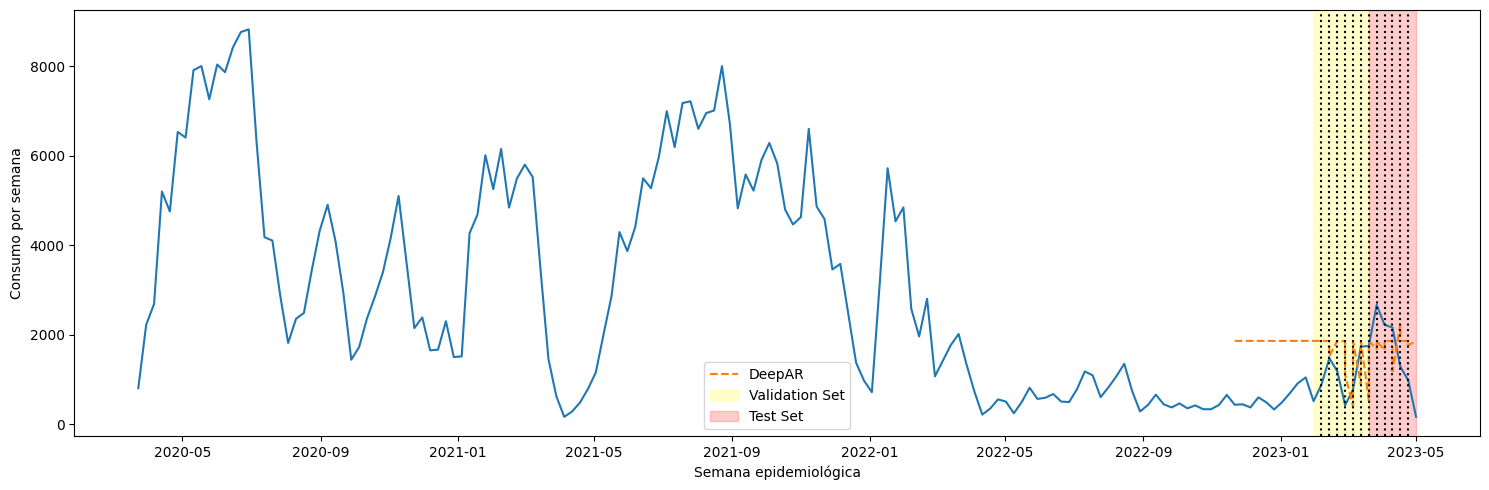

In [ ]:
##########
# DeepAR #
##########

# Particion de datos para el automodelo
aux_train, *_ = TimeSeriesDataset.from_df(Y_train_df)
aux_test, *_ = TimeSeriesDataset.from_df(Y_test_df)
aux_conf = {'input_size': tune.randint(4, 20), 'lstm_hidden_size': tune.randint(1, 20), 'lstm_n_layers': tune.randint(1, 8), 'lstm_dropout': tune.uniform(0.0, 0.5),
            'learning_rate': tune.loguniform(1e-4, 1e-1), 'max_steps': tune.choice([200, 500]), "batch_size": tune.randint(1, 20), 'windows_batch_size': tune.randint(1, 8),
            'random_seed': 1, 'val_check_steps' : tune.randint(1, 10), 'trajectory_samples':tune.randint(50, 200),}

# Configuracion para las pruebas
# aux_conf_retro = {'input_size': tune.randint(4, 20), 'lstm_hidden_size': tune.randint(1, 20), 'lstm_n_layers': tune.randint(1, 8), 'lstm_dropout': tune.uniform(0.0, 0.5),
#           'learning_rate': tune.loguniform(1e-4, 1e-1), 'max_steps': tune.choice([200, 500]), "batch_size": tune.randint(1, 20), 'windows_batch_size': tune.randint(1, 8),
#            'random_seed': 1, 'val_check_steps' : tune.randint(1, 10), 'trajectory_samples':tune.randint(50, 200),}

auto_nf = AutoDeepAR(h=t, config=aux_conf, search_alg = 'hyperopt', num_samples =  n_samp, loss=func_loss)

# Se configura el modelo con los mejores valores encontrados para los hiperparametros
nf = NeuralForecast(
    models=[auto_nf],
    freq='W-Mon'
)

# Entrenamiento
aux = nf.cross_validation(datos_modelado, val_size=max(t_val, t), test_size=t_test, step_size=t_step, n_windows=None, refit=re_entrenar,  )
Y_hat_insample = nf.predict_insample(step_size = t_step)
cutoffs = aux['cutoff'].unique()

# Observaciones de entrenamiento
aux0 = datos_modelado[['ds', 'y',]][:datos_modelado.shape[0] - max(t_val, t) - t_test].reset_index(drop=True)

# Observaciones de prueba
if str(func_loss)[:-2] == 'QuantileLoss':
  aux1 = aux[['ds', 'y', 'AutoDeepAR_ql'+str(aux_ql)]].reset_index(drop=True)
  aux1['AutoDeepAR'] = aux1['AutoDeepAR_ql'+str(aux_ql)]
else:
  aux1 = aux[['ds', 'y', 'AutoDeepAR']].reset_index(drop=True)

# Observaciones de validacion
if str(func_loss)[:-2] == 'QuantileLoss':
  aux2 = Y_hat_insample[Y_hat_insample['cutoff'] >= max(aux0['ds'])].reset_index(drop=True)[['ds', 'y', 'AutoDeepAR_ql'+str(aux_ql)]]
  aux2['AutoDeepAR'] = aux2['AutoDeepAR_ql'+str(aux_ql)]
else:
  aux2 = Y_hat_insample[Y_hat_insample['cutoff'] >= max(aux0['ds'])].reset_index(drop=True)[['ds', 'y', 'AutoDeepAR']]

datos_graph = pd.concat([aux0, aux1, aux2]).sort_values(by='ds').reset_index(drop=True)

# Visualizacion al ajuste hecho a los datos de entrenamiento
plt.figure(figsize=(15,5))

# Se grafican datos reales y pronostico generado
plt.plot(datos_graph['ds'], datos_graph['y'])
plt.plot(datos_graph['ds'], datos_graph['DeepAR'], label='DeepAR', ls='--')

# Sombreado de conjuntos de prueba y validacion
plt.axvspan(datos_graph['ds'].iloc[datos_graph.shape[0] - max(t_val, t) - t_test - 1], datos_graph['ds'].iloc[datos_graph.shape[0] - t_test - 1], alpha=0.2, color='yellow', label='Validation Set')
plt.axvspan(datos_graph['ds'].iloc[datos_graph.shape[0] - t_test - 1], datos_graph['ds'].iloc[datos_graph.shape[0] - 1], alpha=0.2, color='red', label='Test Set')

# Ventanas
for cutoff in cutoffs:
    plt.axvline(x=cutoff, color='black', ls=':')

plt.xlabel('Semana epidemiológica')
plt.ylabel('Consumo por semana')
plt.legend()

plt.tight_layout()
plt.show()



### TFT

Predicting ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/1 0:00:00 • 0:00:00 0.00it/s

MAPE obtenido en los datos de validación:0.8783459340021004


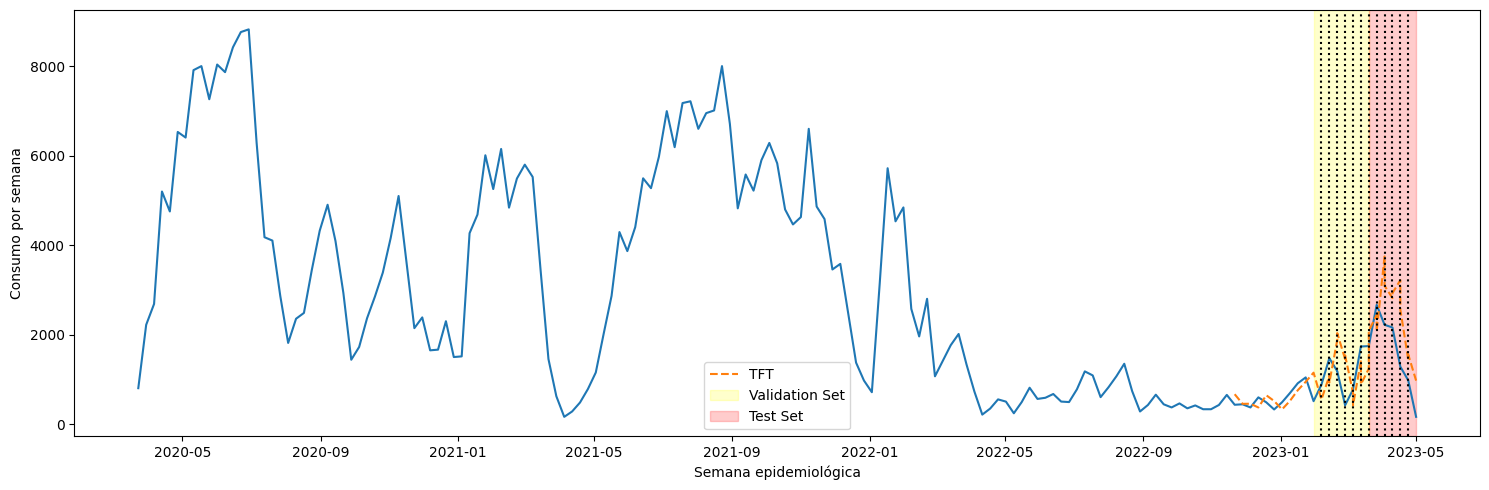

In [ ]:
#######
# TFT #
#######

# Particion de datos para el automodelo
aux_train, *_ = TimeSeriesDataset.from_df(Y_train_df)
aux_test, *_ = TimeSeriesDataset.from_df(Y_test_df)

# Configuracion para las pruebas
aux_conf = {'input_size': tune.randint(4, 20), 'hidden_size': tune.randint(1, 20), 'n_head': tune.randint(1, 8), 'attn_dropout':tune.uniform(0, 1), 'n_rnn_layers':tune.randint(1, 8),
            "learning_rate": tune.loguniform(1e-4, 1e-1), 'max_steps': tune.choice([200, 500]), 'batch_size': tune.randint(1, 20),
            'windows_batch_size': tune.randint(1, 8), 'random_seed': 1, 'val_check_steps' : tune.randint(1, 10), }

# Configuracion para los analisis retorspectivos
# aux_conf_retro = {'input_size': tune.randint(1, 10), 'hidden_size': tune.randint(1, 10), 'n_head': tune.randint(1, 8), 'attn_dropout':tune.uniform(0, 1), 'n_rnn_layers':tune.randint(1, 4),
#            "learning_rate": tune.loguniform(1e-4, 1e-1), 'max_steps': tune.choice([200, 500]), 'batch_size': tune.randint(1, 10),
#            'windows_batch_size': tune.randint(1, 4), 'random_seed': 1, 'val_check_steps' : tune.randint(1, 10), 'start_padding_enabled':True}

auto_nf = AutoTFT(h=t, config=aux_conf, search_alg = 'hyperopt', num_samples =  n_samp, loss=func_loss)

# Se configura el modelo con los mejores valores encontrados para los hiperparametros
nf = NeuralForecast(
    models=[auto_nf],
    freq='W-Mon'
)

# Entrenamiento
aux = nf.cross_validation(datos_modelado, val_size=max(t_val, t), test_size=t_test, step_size=t_step, n_windows=None, refit=re_entrenar,  )
Y_hat_insample = nf.predict_insample(step_size = t_step)
cutoffs = aux['cutoff'].unique()

# Observaciones de entrenamiento
aux0 = datos_modelado[['ds', 'y',]][:datos_modelado.shape[0] - max(t_val, t) - t_test].reset_index(drop=True)

# Observaciones de prueba
if str(func_loss)[:-2] == 'QuantileLoss':
  aux1 = aux[['ds', 'y', 'AutoTFT_ql'+str(aux_ql)]].reset_index(drop=True)
  aux1['AutoTFT'] = aux1['AutoTFT_ql'+str(aux_ql)]
else:
  aux1 = aux[['ds', 'y', 'AutoTFT']].reset_index(drop=True)

# Observaciones de validacion
if str(func_loss)[:-2] == 'QuantileLoss':
  aux2 = Y_hat_insample[Y_hat_insample['cutoff'] >= max(aux0['ds'])].reset_index(drop=True)[['ds', 'y', 'AutoTFT_ql'+str(aux_ql)]]
  aux2['AutoTFT'] = aux2['AutoTFT_ql'+str(aux_ql)]
else:
  aux2 = Y_hat_insample[Y_hat_insample['cutoff'] >= max(aux0['ds'])].reset_index(drop=True)[['ds', 'y', 'AutoTFT']]

datos_graph = pd.concat([aux0, aux1, aux2]).sort_values(by='ds').reset_index(drop=True)

# Visualizacion al ajuste hecho a los datos de entrenamiento
plt.figure(figsize=(15,5))

# Se grafican datos reales y pronostico generado
plt.plot(datos_graph['ds'], datos_graph['y'])
plt.plot(datos_graph['ds'], datos_graph['TFT'], label='TFT', ls='--')

# Sombreado de conjutos de prueba y validacion
plt.axvspan(datos_graph['ds'].iloc[datos_graph.shape[0] - max(t_val, t) - t_test - 1], datos_graph['ds'].iloc[datos_graph.shape[0] - t_test - 1], alpha=0.2, color='yellow', label='Validation Set')
plt.axvspan(datos_graph['ds'].iloc[datos_graph.shape[0] - t_test - 1], datos_graph['ds'].iloc[datos_graph.shape[0] - 1], alpha=0.2, color='red', label='Test Set')

# Ventanas
for cutoff in cutoffs:
    plt.axvline(x=cutoff, color='black', ls=':')

plt.xlabel('Semana epidemiológica')
plt.ylabel('Consumo por semana')
plt.legend()

plt.tight_layout()
plt.show()


### INFORMER



Predicting ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/1 0:00:00 • 0:00:00 0.00it/s

MAPE obtenido en los datos de validación:3.2396975350839647


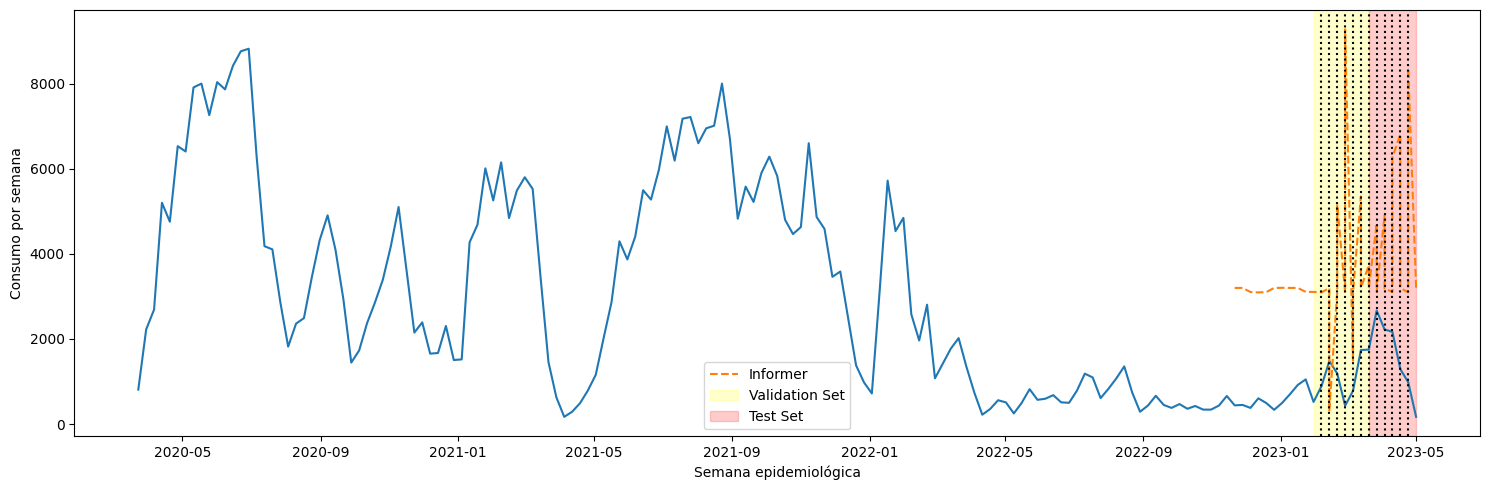

In [ ]:
############
# INFORMER #
############

# Particion de datos para el automodelo
aux_train, *_ = TimeSeriesDataset.from_df(Y_train_df)
aux_test, *_ = TimeSeriesDataset.from_df(Y_test_df)
aux_conf = {'input_size': tune.randint(4, 20), 'hidden_size': tune.randint(1, 20), 'n_head': tune.randint(1, 8),  "learning_rate": tune.loguniform(1e-4, 1e-1),
            'conv_hidden_size': tune.randint(1, 20), 'max_steps': tune.choice([200, 500]), 'batch_size': tune.randint(1, 20), 'windows_batch_size': tune.randint(1, 8),
            'random_seed': 1, 'val_check_steps' : tune.randint(1, 10), }

# Configuracion para las pruebas
# aux_conf_retro = {'input_size': tune.randint(1, 20), 'hidden_size': tune.randint(1, 20), 'n_head': tune.randint(1, 8),  "learning_rate": tune.loguniform(1e-4, 1e-1),
#            'conv_hidden_size': tune.randint(1, 20), 'max_steps': tune.choice([200, 500]), 'batch_size': tune.randint(1, 20), 'windows_batch_size': tune.randint(1, 8),
#            'random_seed': 1, 'val_check_steps' : tune.randint(1, 10), }

auto_nf = AutoInformer(h=t, config=aux_conf, search_alg = 'hyperopt', num_samples =  n_samp, loss=func_loss)

# Se configura el modelo con los mejores valores encontrados para los hiperparametros
nf = NeuralForecast(
    models=[auto_nf],
    freq='W-Mon'
)

# Entrenamiento
aux = nf.cross_validation(datos_modelado, val_size=max(t_val, t), test_size=t_test, step_size=t_step, n_windows=None, refit=re_entrenar,  )
Y_hat_insample = nf.predict_insample(step_size = t_step)
cutoffs = aux['cutoff'].unique()

# Observaciones de entrenamiento
aux0 = datos_modelado[['ds', 'y',]][:datos_modelado.shape[0] - max(t_val, t) - t_test].reset_index(drop=True)

# Observaciones de prueba
if str(func_loss)[:-2] == 'QuantileLoss':
  aux1 = aux[['ds', 'y', 'AutoInformer_ql'+str(aux_ql)]].reset_index(drop=True)
  aux1['AutoInformer'] = aux1['AutoInformer_ql'+str(aux_ql)]
else:
  aux1 = aux[['ds', 'y', 'AutoInformer']].reset_index(drop=True)

# Observaciones de validacion
if str(func_loss)[:-2] == 'QuantileLoss':
  aux2 = Y_hat_insample[Y_hat_insample['cutoff'] >= max(aux0['ds'])].reset_index(drop=True)[['ds', 'y', 'AutoInformer_ql'+str(aux_ql)]]
  aux2['AutoInformer'] = aux2['AutoInformer_ql'+str(aux_ql)]
else:
  aux2 = Y_hat_insample[Y_hat_insample['cutoff'] >= max(aux0['ds'])].reset_index(drop=True)[['ds', 'y', 'AutoInformer']]

datos_graph = pd.concat([aux0, aux1, aux2]).sort_values(by='ds').reset_index(drop=True)

# Visualizacion al ajuste hecho a los datos de entrenamiento
plt.figure(figsize=(15,5))

# Se grafican datos reales y pronostico generado
plt.plot(datos_graph['ds'], datos_graph['y'])
plt.plot(datos_graph['ds'], datos_graph['Informer'], label='Informer', ls='--')

# Sombreado de conjutos de prueba y validacion
plt.axvspan(datos_graph['ds'].iloc[datos_graph.shape[0] - max(t_val, t) - t_test - 1], datos_graph['ds'].iloc[datos_graph.shape[0] - t_test - 1], alpha=0.2, color='yellow', label='Validation Set')
plt.axvspan(datos_graph['ds'].iloc[datos_graph.shape[0] - t_test - 1], datos_graph['ds'].iloc[datos_graph.shape[0] - 1], alpha=0.2, color='red', label='Test Set')

# Ventanas
for cutoff in cutoffs:
    plt.axvline(x=cutoff, color='black', ls=':')

plt.xlabel('Semana epidemiológica')
plt.ylabel('Consumo por semana')
plt.legend()

plt.tight_layout()
plt.show()

### Autoformer

Predicting ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/1 0:00:00 • 0:00:00 0.00it/s

MAPE obtenido en los datos de validación:2.2726006234468197


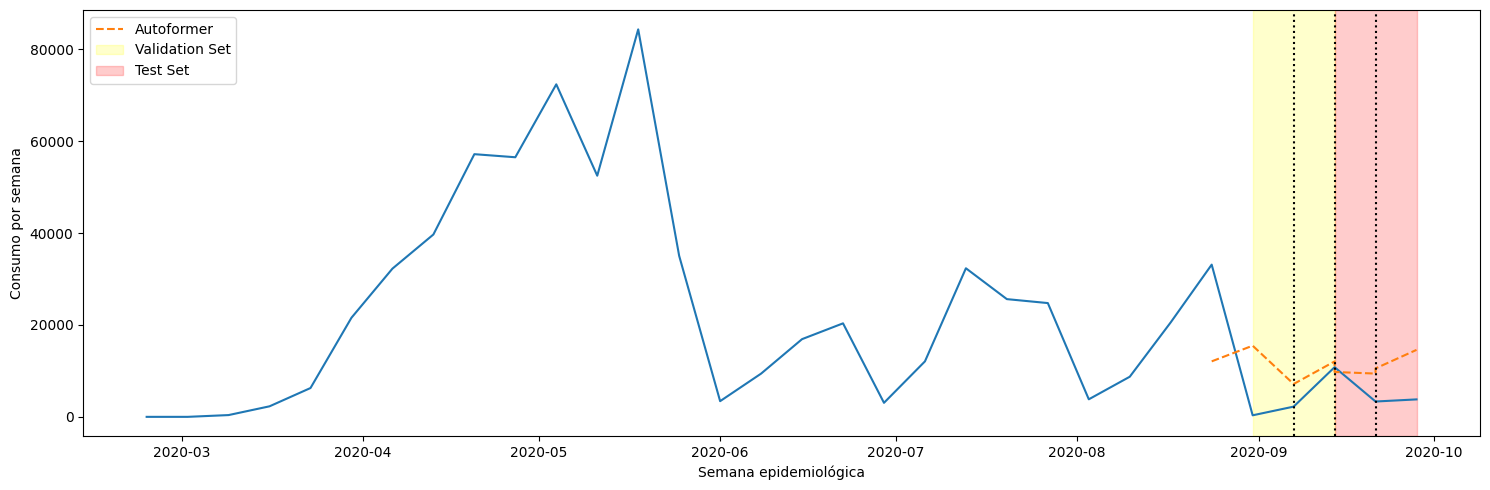

In [ ]:
##############
# AUTOFORMER #
##############

# Particion de datos para el automodelo
aux_train, *_ = TimeSeriesDataset.from_df(Y_train_df)
aux_test, *_ = TimeSeriesDataset.from_df(Y_test_df)
aux_conf = {'input_size': tune.randint(4, 20), 'hidden_size': tune.randint(1, 20), 'n_head': tune.randint(1, 8),  "learning_rate": tune.loguniform(1e-4, 1e-1),
            'conv_hidden_size': tune.randint(1, 20), 'max_steps': tune.choice([200, 500]), 'batch_size': tune.randint(1, 20), 'windows_batch_size': tune.randint(1, 8),
            'random_seed': 1, 'val_check_steps' : tune.randint(1, 10), }

# Configuracion para las pruebas
# aux_conf_retro = {'input_size': tune.randint(4, 20), 'hidden_size': tune.randint(1, 20), 'n_head': tune.randint(1, 8),  "learning_rate": tune.loguniform(1e-4, 1e-1),
#            'conv_hidden_size': tune.randint(1, 20), 'max_steps': tune.choice([200, 500]), 'batch_size': tune.randint(1, 20), 'windows_batch_size': tune.randint(1, 8),
#            'random_seed': 1, 'val_check_steps' : tune.randint(1, 10), }

auto_nf = AutoAutoformer(h=t, config=aux_conf_retro, search_alg = 'hyperopt', num_samples =  n_samp, loss=func_loss, valid_loss = func_loss)

# Se configura el modelo con los mejores valores encontrados para los hiperparametros
nf = NeuralForecast(
    models=[auto_nf],
    freq='W-Mon'
)

# Entrenamiento
aux = nf.cross_validation(datos_modelado, val_size=max(t_val, t), test_size=t_test, step_size=t_step, n_windows=None, refit=re_entrenar,  )
Y_hat_insample = nf.predict_insample(step_size = t_step)
cutoffs = aux['cutoff'].unique()

# Observaciones de entrenamiento
aux0 = datos_modelado[['ds', 'y',]][:datos_modelado.shape[0] - max(t_val, t) - t_test].reset_index(drop=True)

# Observaciones de prueba
if str(func_loss)[:-2] == 'QuantileLoss':
  aux1 = aux[['ds', 'y', 'AutoAutoformer_ql'+str(aux_ql)]].reset_index(drop=True)
  aux1['AutoAutoformer'] = aux1['AutoAutoformer_ql'+str(aux_ql)]
else:
  aux1 = aux[['ds', 'y', 'AutoAutoformer']].reset_index(drop=True)

# Observaciones de validacion
if str(func_loss)[:-2] == 'QuantileLoss':
  aux2 = Y_hat_insample[Y_hat_insample['cutoff'] >= max(aux0['ds'])].reset_index(drop=True)[['ds', 'y', 'AutoAutoformer_ql'+str(aux_ql)]]
  aux2['AutoAutoformer'] = aux2['AutoAutoformer_ql'+str(aux_ql)]
else:
  aux2 = Y_hat_insample[Y_hat_insample['cutoff'] >= max(aux0['ds'])].reset_index(drop=True)[['ds', 'y', 'AutoAutoformer']]

datos_graph = pd.concat([aux0, aux1, aux2]).sort_values(by='ds').reset_index(drop=True)

# Visualizacion al ajuste hecho a los datos de entrenamiento
plt.figure(figsize=(15,5))

# Se grafican datos reales y pronostico generado
plt.plot(datos_graph['ds'], datos_graph['y'])
plt.plot(datos_graph['ds'], datos_graph['Autoformer'], label='Autoformer', ls='--')

# Sombreado de conjutos de prueba y validacion
plt.axvspan(datos_graph['ds'].iloc[datos_graph.shape[0] - max(t_val, t) - t_test - 1], datos_graph['ds'].iloc[datos_graph.shape[0] - t_test - 1], alpha=0.2, color='yellow', label='Validation Set')
plt.axvspan(datos_graph['ds'].iloc[datos_graph.shape[0] - t_test - 1], datos_graph['ds'].iloc[datos_graph.shape[0] - 1], alpha=0.2, color='red', label='Test Set')

# Ventanas
for cutoff in cutoffs:
    plt.axvline(x=cutoff, color='black', ls=':')

plt.xlabel('Semana epidemiológica')
plt.ylabel('Consumo por semana')
plt.legend()

plt.tight_layout()
plt.show()

### TCN

Predicting ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/1 0:00:00 • 0:00:00 0.00it/s

MAPE obtenido en los datos de validación:0.7798697829541422


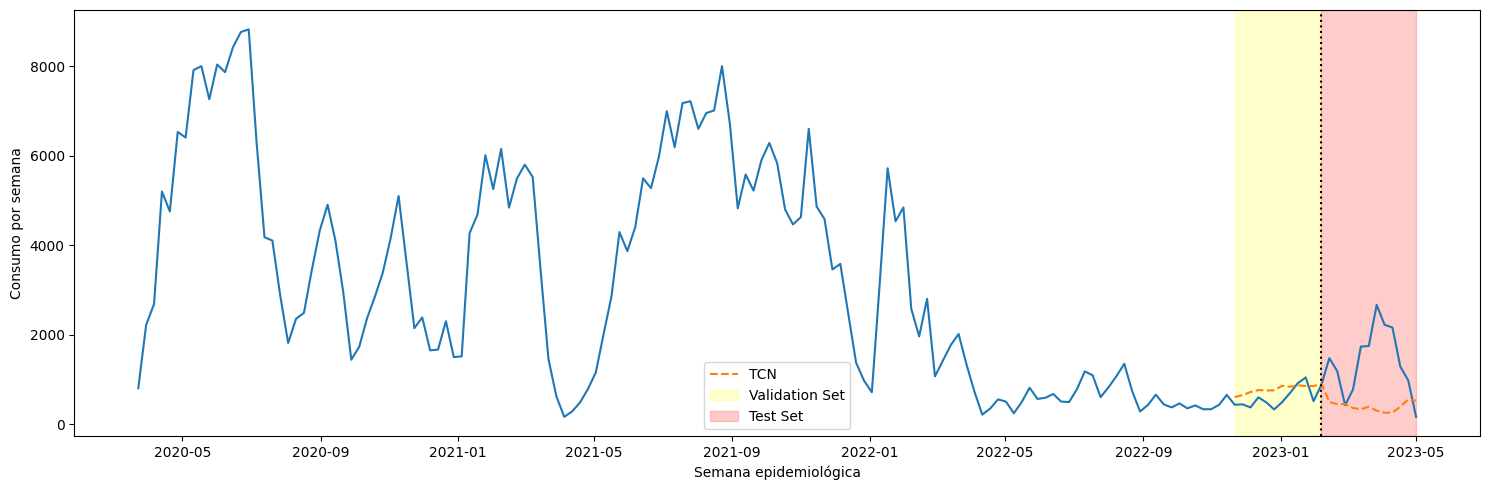

In [ ]:
#######
# TCN #
#######

# Particion de datos para el automodelo
aux_train, *_ = TimeSeriesDataset.from_df(Y_train_df)
aux_test, *_ = TimeSeriesDataset.from_df(Y_test_df)
aux_conf = {'input_size': tune.randint(4, 20), 'context_size': tune.randint(1, 8), 'val_check_steps': tune.randint(1, 10), 'kernel_size' : tune.randint(1, 8), 'decoder_layers': tune.randint(1, 8),
            'decoder_hidden_size': tune.randint(1, 20), 'encoder_hidden_size': tune.randint(1, 20), 'learning_rate': tune.loguniform(1e-4, 1e-1),
            'max_steps': tune.choice([200, 500]), 'batch_size': tune.randint(1, 20), 'random_seed': 1}

# Configuracion para las pruebas
# aux_conf_retro = {'input_size': tune.randint(1, 20), 'context_size': tune.randint(1, 8), 'val_check_steps': tune.randint(1, 10), 'kernel_size' : tune.randint(1, 8), 'decoder_layers': tune.randint(1, 8),
#            'decoder_hidden_size': tune.randint(1, 20), 'encoder_hidden_size': tune.randint(1, 20), 'learning_rate': tune.loguniform(1e-4, 1e-1),
#            'max_steps': tune.choice([200, 500]), 'batch_size': tune.randint(1, 20), 'random_seed': 1}

auto_nf = AutoTCN(h=t, config=aux_conf, search_alg = 'hyperopt', num_samples =  n_samp, loss=func_loss)

# Se configura el modelo con los mejores valores encontrados para los hiperparametros
nf = NeuralForecast(
    models=[auto_nf],
    freq='W-Mon'
)

# Entrenamiento
aux = nf.cross_validation(datos_modelado, val_size=max(t_val, t), test_size=t_test, step_size=t_step, n_windows=None, refit=re_entrenar,  )
Y_hat_insample = nf.predict_insample(step_size = t_step)
cutoffs = aux['cutoff'].unique()

# Observaciones de entrenamiento
aux0 = datos_modelado[['ds', 'y',]][:datos_modelado.shape[0] - max(t_val, t) - t_test].reset_index(drop=True)

# Observaciones de prueba
if str(func_loss)[:-2] == 'QuantileLoss':
  aux1 = aux[['ds', 'y', 'AutoTCN_ql'+str(aux_ql)]].reset_index(drop=True)
  aux1['AutoTCN'] = aux1['AutoTCN_ql'+str(aux_ql)]
else:
  aux1 = aux[['ds', 'y', 'AutoTCN']].reset_index(drop=True)

# Observaciones de validacion
if str(func_loss)[:-2] == 'QuantileLoss':
  aux2 = Y_hat_insample[Y_hat_insample['cutoff'] >= max(aux0['ds'])].reset_index(drop=True)[['ds', 'y', 'AutoTCN_ql'+str(aux_ql)]]
  aux2['AutoTCN'] = aux2['AutoTCN_ql'+str(aux_ql)]
else:
  aux2 = Y_hat_insample[Y_hat_insample['cutoff'] >= max(aux0['ds'])].reset_index(drop=True)[['ds', 'y', 'AutoTCN']]

datos_graph = pd.concat([aux0, aux1, aux2]).sort_values(by='ds').reset_index(drop=True)

# Visualizacion al ajuste hecho a los datos de entrenamiento
plt.figure(figsize=(15,5))

# Se grafican datos reales y pronostico generado
plt.plot(datos_graph['ds'], datos_graph['y'])
plt.plot(datos_graph['ds'], datos_graph['TCN'], label='TCN', ls='--')

# Sombreado de conjutos de prueba y validacion
plt.axvspan(datos_graph['ds'].iloc[datos_graph.shape[0] - max(t_val, t) - t_test], datos_graph['ds'].iloc[datos_graph.shape[0] - t_test-1], alpha=0.2, color='yellow', label='Validation Set')
plt.axvspan(datos_graph['ds'].iloc[datos_graph.shape[0] - t_test - 1], datos_graph['ds'].iloc[datos_graph.shape[0] - 1], alpha=0.2, color='red', label='Test Set')

# Ventanas
for cutoff in cutoffs:
    plt.axvline(x=cutoff, color='black', ls=':')

plt.xlabel('Semana epidemiológica')
plt.ylabel('Consumo por semana')
plt.legend()

plt.tight_layout()
plt.show()